# 대화 히스토리와 질문 재작성

이 절은 앞서 주고받은 말을 「대화 기록」이라고 부릅니다.

**이 노트북에서 할 일**

1. Ch 12에서 쓰던 문서 열두 건과 질문 여덟 개를 그대로 읽습니다.
2. 대상이 빠진 후속 질문을 그대로 검색해 정답 문서의 자리를 봅니다.
3. 대화 기록을 함께 넣어 혼자서도 뜻이 통하는 질문으로 바꿉니다.
4. 바꾼 질문으로 다시 검색하고 찾은 원문만 넣어 답을 받습니다.
5. 대화 기록만 빼고 같은 자리를 다시 재어 견줍니다.

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
서비스 요청은 여덟 번입니다(임베딩 다섯 번과 답 모델 세 번).
예상 비용은 미화 0.01달러 아래입니다.
읽어 오는 파일은 이 챕터 폴더의 문서 파일과 질문 파일 둘이고 새로 쓰는 파일은 없습니다.
실행 시간은 2분 안팎이고 첫 셀의 설치가 가장 오래 걸립니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3~8절을 읽습니다.
Ch 12 검색 부품을 준비하고 후속 질문을 그대로 검색해 보는 자리입니다.
9절부터 12절은 대화 기록을 넣어 질문을 바꾸고 다시 검색해 답까지 받는 자리입니다.
13절과 14절은 대화 기록만 빼고 같은 자리를 다시 재어 견주는 자리입니다.

실습 폴더 `labs/part4/ch14-rag-patterns`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

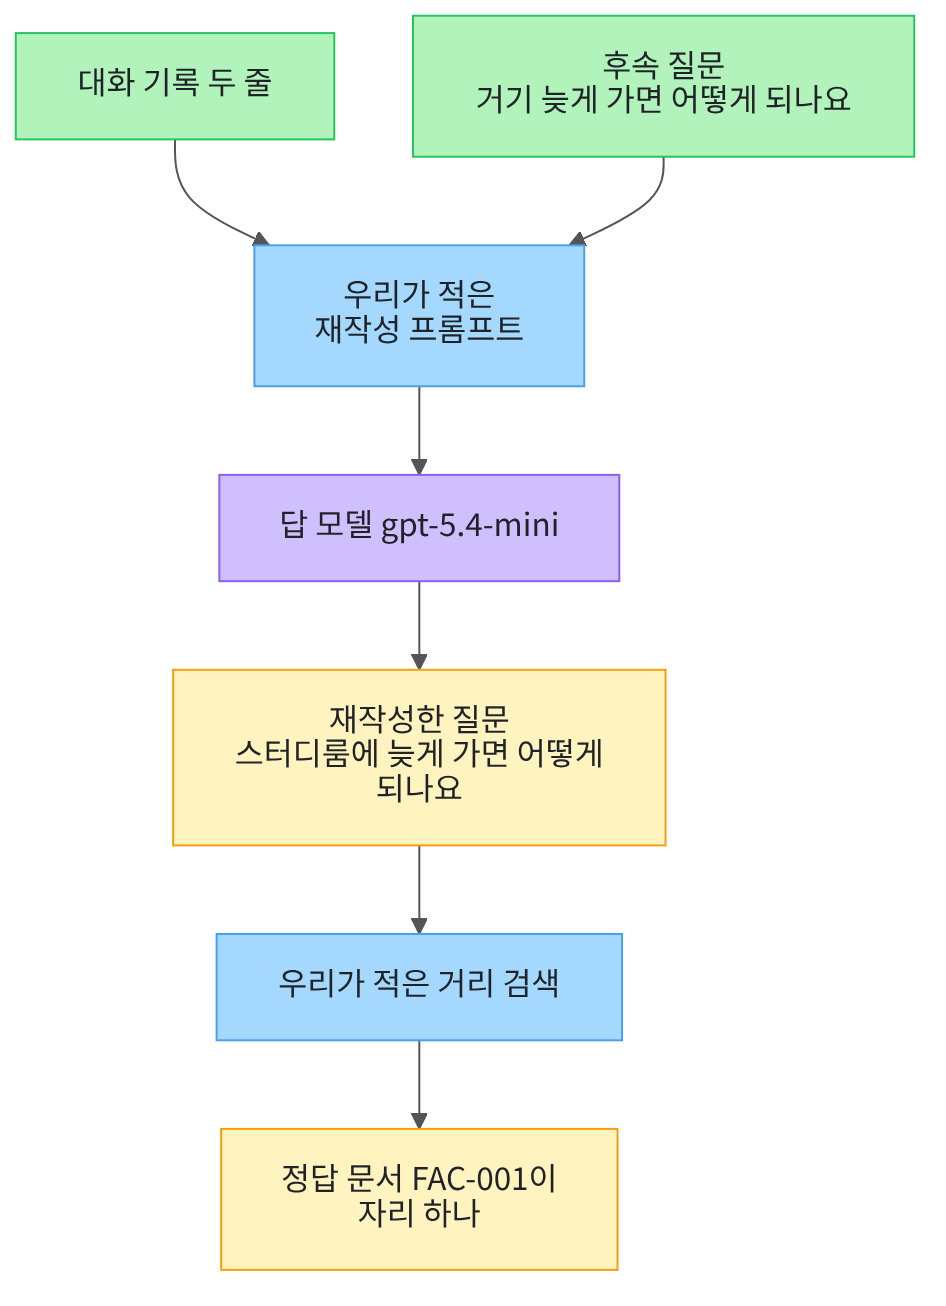

위에서 아래로 읽습니다.
맨 위 초록 상자 둘이 모델에 넣을 자료입니다.
가운데 파란 상자가 우리가 적는 글이고 보라 상자가 모델입니다.
맨 아래 노란 상자 둘이 출력으로 확인한 값입니다.

## 1. 준비

첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3


**결과 읽기** — 설치가 끝나면 판 번호 세 줄이 보입니다.
이 노트북의 출력은 2026-09-19에 이 판으로 실행한 결과입니다.

다음 셀은 이름 다섯 개를 불러옵니다.
앞의 셋은 자료 읽기와 제곱근과 자리 확인에 씁니다.
뒤의 둘은 Ch 9~13에서 쓴 임베딩과 답 모델 이름입니다.

In [2]:
# 자료 읽기·제곱근·경로 확인과 임베딩·답 모델 이름을 불러옵니다
import json
import math
import os

from langchain_openai import OpenAIEmbeddings
from langchain.chat_models import init_chat_model

print("불러온 이름:", "json", "math", "os", "OpenAIEmbeddings", "init_chat_model")

불러온 이름: json math os OpenAIEmbeddings init_chat_model


**결과 읽기** — 출력 줄에 불러온 이름 다섯 개가 보입니다.
이름 `OpenAIEmbeddings`와 `init_chat_model`은 Ch 12·13에서 쓴 것과 같습니다.

## 2. 키와 모델 준비

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-19에 이 모델로 실행한 결과입니다.

## 3. 문서와 질문 읽기

이 절은 이 챕터 폴더의 문서 파일과 질문 파일을 읽습니다.
두 파일은 Ch 12 core 벌 파일과 바이트가 같은 사본입니다.
먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch14-rag-patterns/data"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄 `고른 경로` 뒤에 점 하나나 위로 올라가는 자리가 보입니다.
Ch 10~13에서 쓴 자리 찾기와 같은 코드입니다.
후보 셋 가운데 이 챕터 자료 폴더가 있는 자리를 고릅니다.

다음 셀은 문서 파일과 질문 파일을 읽습니다.

In [6]:
# 이 챕터 폴더의 문서 파일과 질문 파일을 읽습니다(읽기만 하고 고치지 않습니다)
data_path = root_path + "/labs/part4/ch14-rag-patterns/data"
with open(data_path + "/documents.json", encoding="utf-8") as file:
    docs = json.loads(file.read())
with open(data_path + "/queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
print("문서 수:", len(docs))
print("질문 수:", len(queries))

문서 수: 12
질문 수: 8


**결과 읽기** — 출력 줄 `문서 수: 12`와 `질문 수: 8`이 Ch 12 core 벌 그대로입니다.
문서는 도서관 안내 열두 건입니다.

질문 번호는 C01부터 C08까지이고 질문 파일에 적혀 있습니다.
이 절은 그 가운데 질문 하나만 Ch 12 값과 맞춰 보는 데 씁니다.

## 4. 이 절에서 쓸 값 정하기

Ch 12 01~06절에서 정한 값을 그대로 다시 적습니다.
같은 값을 써야 Ch 12 결과와 이 절 결과를 견줄 수 있습니다.

In [7]:
# Ch 12 01~06절에서 쓴 값을 그대로 다시 정합니다
similarity_top = 1
top_three = 3
top_all = 12
print("코사인 유사도의 가장 큰 값:", similarity_top)
print("나란히 볼 상위 문서 수:", top_three)
print("자리를 셀 때 재는 문서 수:", top_all)

코사인 유사도의 가장 큰 값: 1
나란히 볼 상위 문서 수: 3
자리를 셀 때 재는 문서 수: 12


**결과 읽기** — 출력 줄 `코사인 유사도의 가장 큰 값: 1`은 Ch 12 01절에서 정한 값입니다.
출력 줄 `나란히 볼 상위 문서 수: 3`은 표로 볼 자리 수입니다.
출력 줄 `자리를 셀 때 재는 문서 수: 12`는 정답 자리를 끝까지 세려고 둔 값입니다.

## 5. Ch 12 검색 부품 준비

다음 여섯 셀은 Ch 12에서 이미 읽은 코드입니다.
읽지 말고 실행만 하고 넘어가도 됩니다.
문서 글을 이어 붙이고 거리 함수 네 개와 순위 함수 하나를 다시 정의합니다.
문서 ID를 모으는 함수와 정답 자리를 세는 함수와 출력 함수도 함께 준비합니다.

In [8]:
# 문서 12개의 제목과 본문을 이어 붙이고 문서 ID 목록도 만듭니다(Ch 12 06절과 같은 코드)
doc_texts = []
doc_ids = []
for doc in docs:
    doc_texts.append(doc["title"] + " " + doc["text"])
    doc_ids.append(doc["doc_id"])
print("이어 붙인 글 수:", len(doc_texts))
print("첫 문서 글:", doc_texts[0])
print("문서 ID 목록:")
print(doc_ids)

이어 붙인 글 수: 12
첫 문서 글: 도서 대출 기간 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.
문서 ID 목록:
['LIB-001', 'LIB-002', 'LIB-003', 'LIB-004', 'FAC-001', 'FAC-002', 'FAC-003', 'FAC-004', 'ACC-001', 'ACC-002', 'ACC-003', 'ACC-004']


In [9]:
# 문서 ID로 그 문서의 글을 찾을 짝을 만듭니다(답을 만들 때 원문을 넣으려고 씁니다)
text_by_doc = {}
for i in range(len(doc_ids)):
    text_by_doc[doc_ids[i]] = doc_texts[i]
print("짝의 수:", len(text_by_doc))

짝의 수: 12


In [10]:
# Ch 12 01절 점곱·길이·코사인 유사도·코사인 거리를 같은 코드로 다시 정의합니다
def dot_product(first, second):
    total = 0
    # 반복 번호 i로 두 벡터의 같은 자리 숫자를 짝지어 곱하고 더합니다
    for i in range(len(first)):
        total = total + first[i] * second[i]
    return total


def vector_length(vector):
    squared_sum = dot_product(vector, vector)
    return math.sqrt(squared_sum)


def cosine_similarity(first, second):
    dot = dot_product(first, second)
    length_product = vector_length(first) * vector_length(second)
    return dot / length_product


def cosine_distance(first, second):
    similarity = cosine_similarity(first, second)
    return similarity_top - similarity

In [11]:
# Ch 12 05절 거리 순위 만들기를 같은 코드로 다시 정의합니다
def rank_by_distance(question_vector, top_count):
    pairs = []
    for i in range(len(doc_ids)):
        distance = cosine_distance(question_vector, doc_vectors[i])
        pairs.append((distance, doc_ids[i]))
    hit_list = []
    # sorted(목록)는 튜플의 첫 값인 거리를 작은 값부터 정렬합니다
    for pair in sorted(pairs):
        hit_list.append({"doc_id": pair[1], "거리": round(pair[0], 2)})
    return hit_list[:top_count]

In [12]:
# Ch 11 01절 문서 ID 모으기와 정답 자리 세기를 같은 코드로 다시 정의합니다
def unique_doc_ids(hit_list):
    doc_ids = []
    for hit in hit_list:
        if hit["doc_id"] not in doc_ids:
            doc_ids.append(hit["doc_id"])
    return doc_ids


def find_gold_rank(doc_ids, gold_doc_ids):
    gold_rank = 0
    for position in range(len(doc_ids)):
        if doc_ids[position] in gold_doc_ids:
            gold_rank = position + 1
            break
    return gold_rank

In [13]:
# Ch 12 05절 순위 목록 출력 함수를 같은 코드로 다시 정의합니다
def print_ranked(hit_list, value_name):
    print("순위 | 문서 ID |", value_name)
    for rank_number in range(len(hit_list)):
        row = hit_list[rank_number]
        print(rank_number + 1, "|", row["doc_id"], "|", row[value_name])

준비 셀 여섯 개를 지났습니다.
다음 셀은 문서 열두 건을 벡터로 바꿉니다.
이 절에서 서비스에 보내는 첫 요청입니다.

In [14]:
# Ch 12와 같은 모델로 문서 12개를 벡터로 바꿉니다(임베딩 요청 1번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
doc_vectors = embedding_model.embed_documents(doc_texts)
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 벡터 수:", len(doc_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 벡터 수: 12


**결과 읽기** — 출력 줄 `임베딩 모델 이름: text-embedding-3-small`은 Ch 9~13이 쓴 모델과 같습니다.
출력 줄 `벡터의 숫자 개수 설정: 256`도 Ch 10~13과 같은 값입니다.
출력 줄 `문서 벡터 수: 12`로 문서마다 벡터 하나를 받았습니다.
벡터 안의 숫자는 호출마다 아주 조금씩 달라져 소수 자리까지 같다고 보지 않습니다.

## 6. Ch 12와 같은 조건인지 확인

검색 부품이 Ch 12와 같게 움직이는지 먼저 봅니다.
질문 `C01`을 같은 조건으로 재면 Ch 12 05절과 같은 세 문서가 나와야 합니다.

In [15]:
# Ch 12 05절이 쓴 첫 질문을 같은 조건으로 재어 봅니다(임베딩 요청 1번)
first_query = queries[0]
first_vector = embedding_model.embed_query(first_query["question"])
first_hits = rank_by_distance(first_vector, top_three)
print("고른 질문:", first_query["qid"], "|", first_query["question"])
print("그 질문의 정답 문서 ID:", first_query["gold_doc_id"])
print_ranked(first_hits, "거리")

고른 질문: C01 | 책을 빌릴 수 있는 기간은 며칠인가요?
그 질문의 정답 문서 ID: LIB-001
순위 | 문서 ID | 거리
1 | LIB-004 | 0.43
2 | LIB-001 | 0.56
3 | LIB-003 | 0.62


**결과 읽기** — 출력 줄 `고른 질문: C01` 아래 순위 표가 있습니다.
표의 차례는 `LIB-004`와 `LIB-001`과 `LIB-003`이고 Ch 12 05절과 같습니다.
표의 정답 문서 `LIB-001`은 둘째 자리입니다.

거리 값은 소수 둘째 자리까지만 읽습니다.
셋째 자리 아래는 호출마다 조금씩 달라져 본문과 그림에 넣지 않았습니다.

## 7. 대화 기록과 후속 질문 정하기

이제 대화 두 줄과 그 뒤에 이어지는 질문 하나를 정합니다.
후속 질문에는 앞 대화를 봐야 뜻이 정해지는 말 「거기」가 들어 있습니다.
이 질문의 정답 문서와 재작성 뒤에도 남아야 할 낱말도 함께 적어 둡니다.

In [16]:
# 앞선 대화 두 줄과 대상이 빠진 후속 질문을 정합니다
history_lines = []
history_lines.append("사용자: 스터디룸은 몇 명부터 예약할 수 있나요?")
history_lines.append("도우미: 두 명 이상이면 예약할 수 있습니다.")
follow_up = "거기 늦게 가면 어떻게 되나요?"
gold_doc_id = "FAC-001"
keep_word = "스터디룸"
print("대화 기록 줄 수:", len(history_lines))
print("후속 질문:", follow_up)
print("이 질문의 정답 문서 ID:", gold_doc_id, "| 남아야 할 낱말:", keep_word)

대화 기록 줄 수: 2
후속 질문: 거기 늦게 가면 어떻게 되나요?
이 질문의 정답 문서 ID: FAC-001 | 남아야 할 낱말: 스터디룸


**결과 읽기** — 출력 줄 `대화 기록 줄 수: 2`로 앞선 대화가 두 줄입니다.
출력 줄 `후속 질문: 거기 늦게 가면 어떻게 되나요?`에는 스터디룸이라는 말이 없습니다.
출력 줄의 `이 질문의 정답 문서 ID: FAC-001`은 우리가 정한 정답입니다.
같은 줄의 `남아야 할 낱말: 스터디룸`은 재작성 결과를 볼 때 쓸 낱말입니다.

## 8. 재작성 없이 검색하기

실행 전에 예상해 봅니다.
질문에 「늦게」가 있으니 연체를 다룬 문서가 앞으로 올 것입니다.
스터디룸이라는 말이 없어 정답 문서는 뒤로 밀릴 것입니다.

In [17]:
# 후속 질문을 그대로 재어 정답 문서가 몇째 자리인지 봅니다(임베딩 요청 1번)
before_vector = embedding_model.embed_query(follow_up)
before_hits = rank_by_distance(before_vector, top_all)
before_ids = unique_doc_ids(before_hits)
before_place = find_gold_rank(before_ids, [gold_doc_id])
print_ranked(before_hits[:top_three], "거리")
print("재작성 전 정답 문서의 자리:", before_place)

순위 | 문서 ID | 거리
1 | LIB-002 | 0.75
2 | ACC-001 | 0.82
3 | ACC-002 | 0.84
재작성 전 정답 문서의 자리: 8


**결과 읽기** — 순위 표의 첫 자리는 `LIB-002`이고 연체를 다룬 문서입니다.
출력 줄 `재작성 전 정답 문서의 자리: 8`로 정답 문서는 여덟째 자리였습니다.
질문에 대상이 없으니 검색은 「늦게」라는 말만 보고 문서를 골랐습니다.

## 9. 재작성 프롬프트 만들기

모델에 넣을 머리글 두 개를 먼저 적어 둡니다.
앞의 머리글은 질문을 바꾸는 일에 쓰고 뒤의 머리글은 답을 만드는 일에 씁니다.
새 조건을 보태지 말라는 줄을 넣어 없던 날짜나 이름이 붙는 것을 막습니다.

In [18]:
# 모델에 넣을 머리글 두 개를 미리 적어 둡니다
rewrite_head = "아래 대화 기록을 보고 마지막 질문을 혼자서도 뜻이 통하는 검색 질문 한 문장으로 바꾸세요.\n"
rewrite_head = rewrite_head + "새 조건을 보태지 말고 질문 한 문장만 적으세요.\n\n"
answer_head = "아래 자료만 보고 질문에 한국어로 한 문장으로 답하세요.\n"
answer_head = answer_head + "답 끝에 [문서ID] 모양으로 출처를 적으세요.\n\n"
print("재작성 머리글:")
print(rewrite_head)
print("답 만들기 머리글:")
print(answer_head)

재작성 머리글:
아래 대화 기록을 보고 마지막 질문을 혼자서도 뜻이 통하는 검색 질문 한 문장으로 바꾸세요.
새 조건을 보태지 말고 질문 한 문장만 적으세요.


답 만들기 머리글:
아래 자료만 보고 질문에 한국어로 한 문장으로 답하세요.
답 끝에 [문서ID] 모양으로 출처를 적으세요.




**결과 읽기** — 라벨 줄 `재작성 머리글:` 아래에 두 문장이 있습니다.
라벨 줄 `답 만들기 머리글:` 아래에는 자료만 보고 답하라는 두 문장이 있습니다.
두 머리글 모두 우리가 적은 글이고 모델이 만든 글이 아닙니다.

다음 셀은 머리글과 대화 기록과 마지막 질문을 한 글로 잇는 함수입니다.

In [19]:
# 머리글과 대화 기록과 마지막 질문을 한 글로 이어 붙입니다
def build_rewrite_prompt(history_lines, question):
    history_text = ""
    for line in history_lines:
        history_text = history_text + line + "\n"
    prompt_text = rewrite_head + "대화 기록:\n" + history_text
    prompt_text = prompt_text + "\n마지막 질문: " + question
    return prompt_text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `build_rewrite_prompt`는 대화 기록 줄을 하나씩 이어 한 덩어리 글로 만듭니다.
그 뒤에 마지막 질문을 붙여 모델에 넣을 글 하나를 만듭니다.
대화 기록이 빈 목록이면 기록 자리가 빈 채로 남습니다.

다음 셀은 그 글을 만들어 모델에 넣습니다.

In [20]:
# 만든 글을 모델에 넣어 혼자서도 뜻이 통하는 질문을 받습니다(모델 요청 1번)
rewrite_prompt = build_rewrite_prompt(history_lines, follow_up)
print("모델에 넣을 글:")
print(rewrite_prompt)
rewrite_reply = model.invoke(rewrite_prompt)
rewritten = rewrite_reply.text.strip()
print("재작성한 질문:", rewritten)

모델에 넣을 글:
아래 대화 기록을 보고 마지막 질문을 혼자서도 뜻이 통하는 검색 질문 한 문장으로 바꾸세요.
새 조건을 보태지 말고 질문 한 문장만 적으세요.

대화 기록:
사용자: 스터디룸은 몇 명부터 예약할 수 있나요?
도우미: 두 명 이상이면 예약할 수 있습니다.

마지막 질문: 거기 늦게 가면 어떻게 되나요?


재작성한 질문: 스터디룸에 늦게 가면 어떻게 되나요?


**결과 읽기** — 라벨 줄 `모델에 넣을 글:` 아래에 머리글과 대화 기록과 마지막 질문이 차례로 있습니다.
출력 줄 `재작성한 질문: 스터디룸에 늦게 가면 어떻게 되나요?`에는 대상이 채워져 있습니다.
모델은 대화 기록에서 「거기」가 가리키는 대상을 찾아 넣었습니다.
답 문장은 실행마다 달라질 수 있어 이 값에 `assert`를 걸지 않았습니다.

## 10. 대상 낱말이 남았는지 보기

재작성은 검색 입력을 고치는 일이라 대상이 빠지면 뜻이 달라집니다.
그래서 낱말 하나가 글에 있는지만 보는 짧은 검사 함수를 만듭니다.

In [21]:
# 글 안에 찾는 낱말이 있는지만 보는 검사 함수를 만듭니다
def keeps_word(sentence, word):
    found = word in sentence
    return found

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `keeps_word`는 낱말이 글 안에 있으면 참을 냅니다.
답이 맞는지 재는 함수가 아니라 낱말이 있는지만 보는 함수입니다.

다음 셀은 후속 질문과 재작성한 질문을 그 함수로 봅니다.

In [22]:
# 후속 질문과 재작성한 질문에 대상 낱말이 있는지 봅니다
print("찾는 낱말:", keep_word)
print("후속 질문에 있는가:", keeps_word(follow_up, keep_word))
print("재작성한 질문에 있는가:", keeps_word(rewritten, keep_word))

찾는 낱말: 스터디룸
후속 질문에 있는가: False
재작성한 질문에 있는가: True


**결과 읽기** — 출력 줄 `후속 질문에 있는가: False`로 처음 질문에는 대상이 없었습니다.
출력 줄 `재작성한 질문에 있는가: True`로 바꾼 질문에는 대상이 들어왔습니다.
두 줄의 차이가 이 절이 보려던 것입니다.

## 11. 재작성한 질문으로 검색하기

실행 전에 예상해 봅니다.
질문에 스터디룸이 들어왔으니 스터디룸 예약 문서가 앞으로 올 것입니다.

In [23]:
# 재작성한 질문으로 다시 재어 정답 문서의 자리를 봅니다(임베딩 요청 1번)
after_vector = embedding_model.embed_query(rewritten)
after_hits = rank_by_distance(after_vector, top_all)
after_ids = unique_doc_ids(after_hits)
after_place = find_gold_rank(after_ids, [gold_doc_id])
print_ranked(after_hits[:top_three], "거리")
print("재작성 뒤 정답 문서의 자리:", after_place)

순위 | 문서 ID | 거리
1 | FAC-001 | 0.42
2 | FAC-004 | 0.73
3 | ACC-001 | 0.76
재작성 뒤 정답 문서의 자리: 1


**결과 읽기** — 순위 표의 첫 자리가 `FAC-001`로 바뀌었습니다.
출력 줄 `재작성 뒤 정답 문서의 자리: 1`로 정답 문서가 첫 자리에 왔습니다.
같은 문서 열두 건에서 질문만 바꿨는데 고른 문서가 달라졌습니다.

## 12. 찾은 원문으로 답 만들기

검색이 고른 앞자리 세 문서의 원문만 모델에 넣습니다.
모델이 만든 재작성 질문은 검색 입력일 뿐이라 출처로 쓰지 않습니다.
출처로 쓰는 것은 자료에 있는 문서 ID와 그 원문입니다.

In [24]:
# 앞자리 문서의 원문과 문서 ID를 이어 답 만들기 프롬프트를 만듭니다
def build_answer_prompt(question, hit_list):
    material = ""
    for hit in hit_list:
        doc_id = hit["doc_id"]
        material = material + "[" + doc_id + "] " + text_by_doc[doc_id] + "\n"
    prompt_text = answer_head + "질문: " + question + "\n\n자료:\n" + material
    return prompt_text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `build_answer_prompt`는 문서 ID를 대괄호로 묶고 그 아래 원문을 붙입니다.
그렇게 만든 자료 덩어리를 머리글과 질문 뒤에 이어 붙입니다.

다음 셀은 그 글을 모델에 넣어 답을 받습니다.

In [25]:
# 찾은 원문 세 건만 넣어 답을 받습니다(모델 요청 1번)
answer_prompt = build_answer_prompt(rewritten, after_hits[:top_three])
answer_reply = model.invoke(answer_prompt)
answer = answer_reply.text.strip()
print("정답 문서 ID:", gold_doc_id)
print("모델이 쓴 답:")
print(answer)
print("답에 정답 문서 ID 표시가 있는가:", keeps_word(answer, gold_doc_id))

정답 문서 ID: FAC-001
모델이 쓴 답:
스터디룸은 예약 시작 후 10분 안에 입실하지 않으면 예약이 취소됩니다. [FAC-001]
답에 정답 문서 ID 표시가 있는가: True


**결과 읽기** — 출력 줄 `정답 문서 ID: FAC-001`이 우리가 정한 정답입니다.
라벨 줄 `모델이 쓴 답:` 아래 한 문장에 늦게 입실했을 때의 처리가 적혀 있습니다.
출력 줄 `답에 정답 문서 ID 표시가 있는가: True`로 답 끝에 출처 표시가 붙었습니다.
답 문장은 실행마다 달라질 수 있어 문장 속 낱말에 `assert`를 걸지 않았습니다.

## 13. 값 바꿔 보기 · 대화 기록을 빼고 재작성

바꿀 값은 대화 기록 하나입니다.
머리글도 후속 질문도 그대로 두고 기록만 빈 목록으로 바꿉니다.
실행 전에 예상해 봅니다.
대상을 찾을 자리가 없으니 「거기」가 그대로 남을 것입니다.

In [26]:
# 대화 기록만 빈 목록으로 바꿔 같은 후속 질문을 다시 재작성합니다(모델 요청 1번)
empty_history = []
empty_prompt = build_rewrite_prompt(empty_history, follow_up)
empty_reply = model.invoke(empty_prompt)
empty_rewritten = empty_reply.text.strip()
print("대화 기록 없이 재작성한 질문:", empty_rewritten)
print("그 질문에 낱말이 있는가:", keeps_word(empty_rewritten, keep_word))

대화 기록 없이 재작성한 질문: 거기에 늦게 가면 어떻게 되나요?
그 질문에 낱말이 있는가: False


**결과 읽기** — 출력 줄 `그 질문에 낱말이 있는가: False`로 대상이 채워지지 않았습니다.
바꾼 질문에도 앞 대화를 봐야 뜻이 정해지는 말이 그대로 남았습니다.
모델이 게을러서가 아니라 채울 자료를 주지 않았기 때문입니다.

이 자리의 문장은 실행마다 조금씩 달라집니다.
새 커널로 두 번 실행했을 때 한 번은 「거기 늦게 가면」, 한 번은 「거기에 늦게 가면」이 나왔습니다.

다음 셀은 그 질문으로 다시 검색합니다.

In [27]:
# 대화 기록 없이 재작성한 질문으로 재어 봅니다(임베딩 요청 1번)
empty_vector = embedding_model.embed_query(empty_rewritten)
empty_hits = rank_by_distance(empty_vector, top_all)
empty_ids = unique_doc_ids(empty_hits)
empty_place = find_gold_rank(empty_ids, [gold_doc_id])
print_ranked(empty_hits[:top_three], "거리")
print("기록 없이 재작성한 질문의 정답 자리:", empty_place)

순위 | 문서 ID | 거리
1 | LIB-002 | 0.74
2 | ACC-002 | 0.82
3 | ACC-001 | 0.83
기록 없이 재작성한 질문의 정답 자리: 10


**결과 읽기** — 순위 표의 첫 자리는 8절과 같은 `LIB-002`입니다.
출력 줄 `기록 없이 재작성한 질문의 정답 자리: 10`으로 정답 문서는 첫 자리 밖이었습니다.
재작성이라는 단계를 거쳐도 넣을 자료가 없으면 대상이 채워지지 않습니다.

이 자리의 정답 자리는 앞 셀의 문장이 달라지면 함께 달라집니다.
새 커널로 두 번 실행했을 때 한 번은 여덟이었고 한 번은 열이었습니다.
이 노트북에 실린 출력은 열입니다.

## 14. 세 실행을 기록 한 줄씩으로

실행 하나를 기록 한 줄로 만들어 담아 둡니다.
Ch 9~13에서 쓴 기록 한 줄과 같은 모양입니다.

In [28]:
# 실행 한 번을 기록 한 줄로 만듭니다
def run_row(run_name, question_text, found_ids, place):
    row = {"실행": run_name}
    row["검색에 쓴 질문"] = question_text
    row["첫 자리 문서"] = found_ids[0]
    row["정답 자리"] = place
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
담는 칸은 실행 이름과 검색에 쓴 질문과 첫 자리 문서와 정답 자리 넷입니다.
이 절이 견주는 값이 그 넷이기 때문입니다.

다음 셀은 세 실행의 기록을 표로 출력합니다.

In [29]:
# 세 실행의 기록을 담아 라벨 줄 아래에 한 줄씩 출력합니다
run_rows = []
run_rows.append(run_row("재작성 없음", follow_up, before_ids, before_place))
run_rows.append(run_row("기록을 넣은 재작성", rewritten, after_ids, after_place))
run_rows.append(run_row("기록 없는 재작성", empty_rewritten, empty_ids, empty_place))
print("실행 | 검색에 쓴 질문 | 첫 자리 문서 | 정답 자리")
for row in run_rows:
    print(row["실행"], "|", row["검색에 쓴 질문"], "|", row["첫 자리 문서"], "|", row["정답 자리"])

실행 | 검색에 쓴 질문 | 첫 자리 문서 | 정답 자리
재작성 없음 | 거기 늦게 가면 어떻게 되나요? | LIB-002 | 8
기록을 넣은 재작성 | 스터디룸에 늦게 가면 어떻게 되나요? | FAC-001 | 1
기록 없는 재작성 | 거기에 늦게 가면 어떻게 되나요? | LIB-002 | 10


**결과 읽기** — 라벨 줄 `실행 | 검색에 쓴 질문 | 첫 자리 문서 | 정답 자리` 아래 세 줄이 나옵니다.
기록을 넣은 재작성 줄만 첫 자리 문서가 `FAC-001`이고 정답 자리가 하나입니다.
나머지 두 줄은 첫 자리 문서가 `LIB-002`이고 정답 문서가 첫 자리 밖입니다.

## 정리

1. 대상이 빠진 후속 질문을 그대로 검색하니 정답 문서가 여덟째 자리였습니다.
2. 대화 기록을 넣어 대상을 채운 질문으로 검색하니 정답 문서가 첫 자리였습니다.
3. 대화 기록을 빼고 재작성하면 대상이 채워지지 않아 정답 문서가 첫 자리 밖이었습니다.

02절에서는 질문 하나를 여러 개로 늘려 검색합니다.
혼자서도 뜻이 통하는 질문 하나가 그 절의 입력입니다.